## Clasificación Multiclase con CNN 2D: Dataset CIFAR-10

Para este ejemplo, utilizaremos el dataset **CIFAR-10**. Este es un conjunto de datos popular que contiene 60,000 imágenes de 32x32 en color en 10 clases, con 6,000 imágenes por clase. Hay 50,000 imágenes de entrenamiento y 10,000 imágenes de prueba. Las 10 clases son:

* avión
* automóvil
* pájaro
* gato
* ciervo
* perro
* rana
* caballo
* barco
* camión

### Pasos a seguir:

1.  **Cargar y preprocesar los datos**.
2.  **Definir la arquitectura del modelo CNN**.
3.  **Compilar el modelo**.
4.  **Entrenar el modelo**.
5.  **Evaluar el modelo**.

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 294s 2us/step


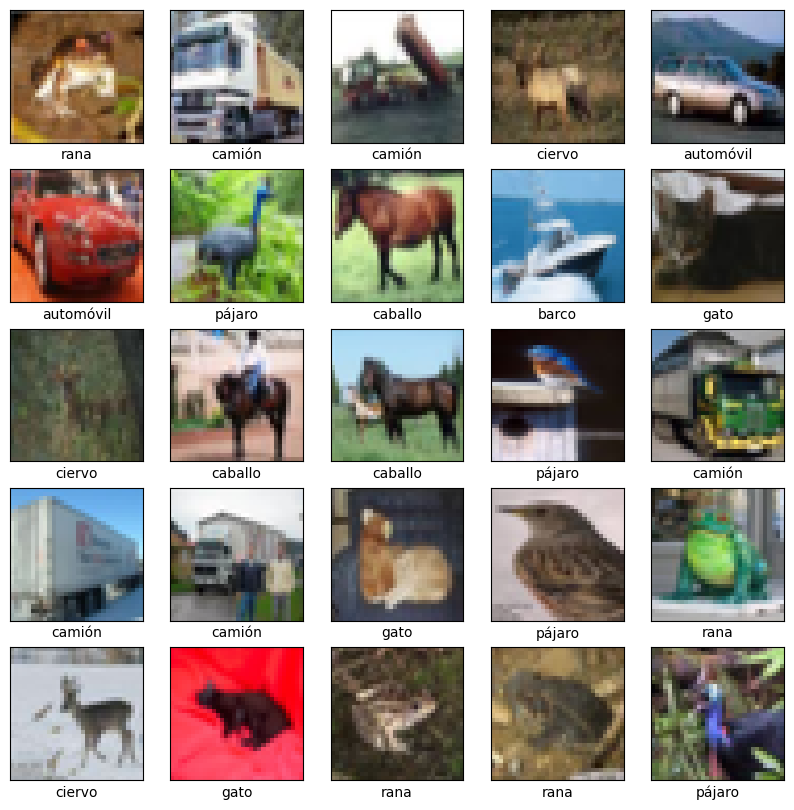

In [4]:
# Importar las librerías necesarias
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np

# Cargar el dataset CIFAR-10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalizar los valores de los píxeles para que estén en el rango [0, 1]
train_images, test_images = train_images / 255.0, test_images / 255.0

# Definir los nombres de las clases
class_names = ['avión', 'automóvil', 'pájaro', 'gato', 'ciervo', 'perro', 'rana', 'caballo', 'barco', 'camión']

# Mostrar algunas imágenes del dataset
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # Las etiquetas CIFAR-10 son arrays de una dimensión, por eso el .flatten()
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

## Definir la Arquitectura de la CNN

Ahora, construiremos la CNN. Utilizaremos una arquitectura sencilla que consta de:

*   **Capas convolucionales (Conv2D)**: Para extraer características de las imágenes.
*   **Capas de Max Pooling (MaxPooling2D)**: Para reducir la dimensionalidad y hacer el modelo más robusto a pequeñas variaciones.
*   **Capas densas (Dense)**: Para la clasificación final después de aplanar la salida de las capas convolucionales.

In [5]:
# Crear el modelo convolucional base
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Mostrar un resumen de la arquitectura del modelo convolucional
model.summary()

# Añadir capas densas para clasificación
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10, activation='softmax')) # 10 clases de salida con activación softmax para clasificación multiclase

# Mostrar un resumen completo del modelo
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

...

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

## Compilar y Entrenar el Modelo

Una vez definida la arquitectura, compilaremos el modelo especificando el optimizador, la función de pérdida y las métricas. Luego, lo entrenaremos usando el conjunto de datos de entrenamiento y lo validaremos con el conjunto de prueba.

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.4428 - loss: 1.5238 - val_accuracy: 0.5290 - val_loss: 1.3160
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5879 - loss: 1.1615 - val_accuracy: 0.6205 - val_loss: 1.0805
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.6476 - loss: 0.9983 - val_accuracy: 0.6578 - val_loss: 0.9753
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6849 - loss: 0.8985 - val_accuracy: 0.6627 - val_loss: 0.9488
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7130 - loss: 0.8176 - val_accuracy: 0.6827 - val_loss: 0.9091
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7312 - loss: 0.7635 - val_accuracy: 0.7004 - val_loss: 0.8562
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7505 - loss: 0.7107 - val_accuracy: 0.7068 - val_loss: 0.8681
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7678 - loss: 0.6660 

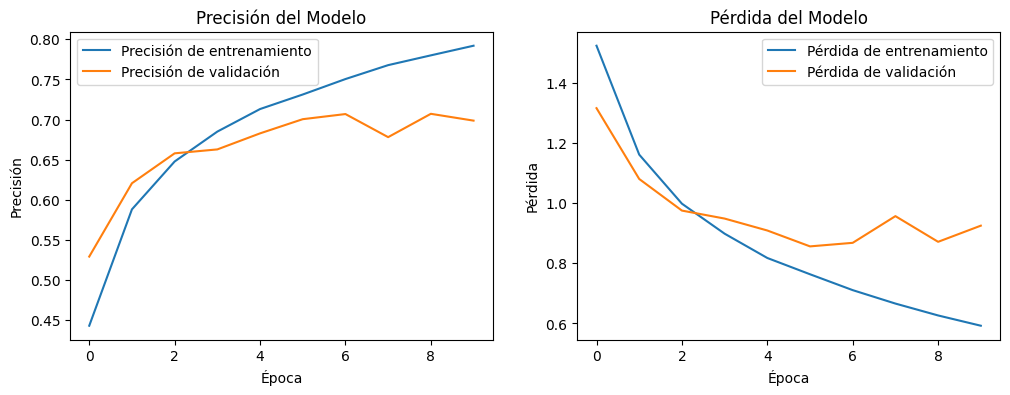

In [6]:
# Compilar el modelo
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=['accuracy'])

# Entrenar el modelo
history = model.fit(train_images, train_labels, epochs=10, # Puedes ajustar el número de épocas
                    validation_data=(test_images, test_labels))

# Visualizar la precisión y la pérdida durante el entrenamiento
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Precisión de entrenamiento')
plt.plot(history.history['val_accuracy'], label='Precisión de validación')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.title('Precisión del Modelo')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Pérdida del Modelo')
plt.show()

## Evaluar el Modelo

Finalmente, evaluaremos el rendimiento del modelo con los datos de prueba.

In [7]:
# Evaluar el modelo
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)
print(f'\nPrecisión en los datos de prueba: {test_acc}')

313/313 - 1s - 3ms/step - accuracy: 0.6986 - loss: 0.9252

Precisión en los datos de prueba: 0.6985999941825867


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
### Matriz de Confusión ###


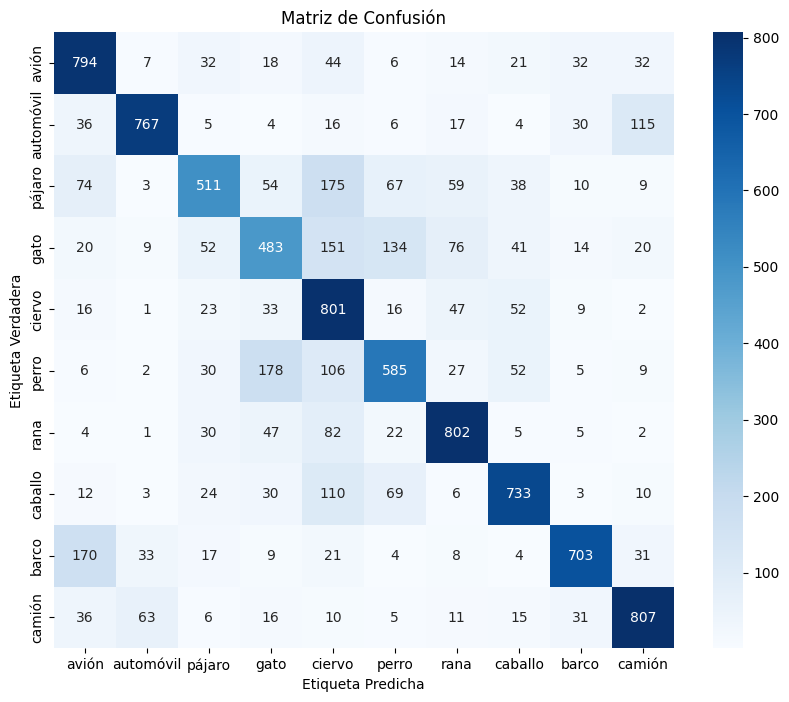


### Reporte de Clasificación por Clase ###
              precision    recall  f1-score   support

       avión       0.68      0.79      0.73      1000
   automóvil       0.86      0.77      0.81      1000
      pájaro       0.70      0.51      0.59      1000
        gato       0.55      0.48      0.52      1000
      ciervo       0.53      0.80      0.64      1000
       perro       0.64      0.58      0.61      1000
        rana       0.75      0.80      0.78      1000
     caballo       0.76      0.73      0.75      1000
       barco       0.83      0.70      0.76      1000
      camión       0.78      0.81      0.79      1000

    accuracy                           0.70     10000
   macro avg       0.71      0.70      0.70     10000
weighted avg       0.71      0.70      0.70     10000



In [8]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Realizar predicciones en el conjunto de prueba
predictions = model.predict(test_images)
predicted_labels = np.argmax(predictions, axis=1)

# Las etiquetas reales necesitan ser aplanadas ya que eran arrays de una dimensión
real_labels = test_labels.flatten()

print('### Matriz de Confusión ###')
# Calcular la matriz de confusión
cm = confusion_matrix(real_labels, predicted_labels)

# Visualizar la matriz de confusión
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Verdadera')
plt.title('Matriz de Confusión')
plt.show()

print('\n### Reporte de Clasificación por Clase ###')
# Generar el reporte de clasificación
report = classification_report(real_labels, predicted_labels, target_names=class_names)
print(report)
